# Outcome: Linear SVM

Linear support vector machine, one-vs-rest. A kernel (RBF) SVM is impractical at ~125k rows.

**Task:** predict each animal's outcome at intake, as one of four classes: Adoption, Transfer, Return to Owner, Euthanasia.
- **Framing:** euthanasia mostly reflects medical or behavioral shelter decisions. In the dashboard this class is shown as **"at-risk / needs attention"**, a prompt to prioritize care, not a judgment about the animal.
- **Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal. Test (2023+) is untouched.
- **Metrics:** macro-F1 (main; each class counts equally), accuracy, per-class precision and recall. Classes are imbalanced: Euthanasia is about 3% of training rows and 2% of val.

**Part 1 uses default hyperparameters.** The only exceptions are settings that don't change the model: `random_state`, `n_jobs`, and an iteration cap where the default doesn't converge.

**Part 2 tunes the model** (`utils.tune_classifier`):
- randomized search, fit on intakes before 2021 and scored by macro-F1 on 2021;
- the best setting is then refit on all training years and scored on the same 2022 val set;
- val and test are never used for selection.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
LABELS = utils.OUTCOME_CLASSES
train, val, test = utils.load_outcome_splits()   # test is held out
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
pd.DataFrame({"train": train["outcome_group"].value_counts(normalize=True),
              "val": val["outcome_group"].value_counts(normalize=True)}).reindex(LABELS).round(3)

time_group_split: dropped 1,274 rows (0.8%) belonging to animals first seen in an earlier split
train 125,490  val 10,430  (test 21,463 untouched)


,train,val
outcome_group,,
Adoption,0.480,0.604
Transfer,0.303,0.271
Return to Owner,0.185,0.103
Euthanasia,0.031,0.021


## Part 1: default hyperparameters

In [2]:
from sklearn.svm import LinearSVC

model = LinearSVC(random_state=utils.SEED)
model

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


== Linear SVM ==  macro-F1 0.395  accuracy 0.656
                 precision    recall  f1-score   support

       Adoption       0.68      0.91      0.78      6300
       Transfer       0.60      0.21      0.31      2830
Return to Owner       0.52      0.46      0.49      1077
     Euthanasia       0.00      0.00      0.00       223

       accuracy                           0.66     10430
      macro avg       0.45      0.40      0.39     10430
   weighted avg       0.63      0.66      0.61     10430



train accuracy 0.638  |  fit 13.3s  predict 0.0s


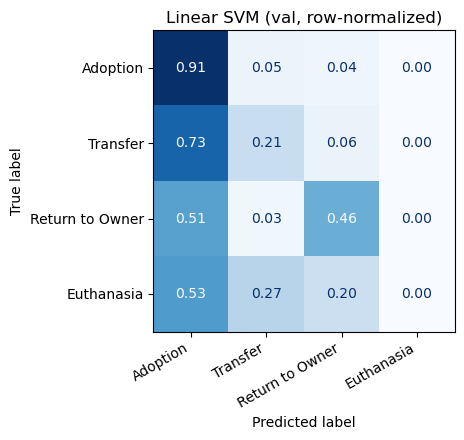

In [3]:
pipe, metrics = utils.evaluate_classifier(
    model, train, val, name="Linear SVM", target="outcome_group", labels=LABELS, ordinal=False,
    results_dir=RESULTS_DIR)

## Part 2: hyperparameter tuning

In [4]:
from scipy.stats import loguniform
base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'C': loguniform(1e-3, 10),
    'class_weight': [None, 'balanced'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Linear SVM (tuned)", n_iter=10, target="outcome_group",
    results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 585 rows (0.5%) belonging to animals first seen in an earlier split


Linear SVM (tuned): 10 candidates in 0.5 min | sub-train 114,369, inner-val 10,536 | best inner-val f1_macro 0.459
best params: {'C': 0.0054167545832474575, 'class_weight': 'balanced'}


,C,class_weight,inner_val_f1_macro,mean_fit_time
0,0.005417,balanced,0.458540,10.817307
1,0.001681,balanced,0.458295,8.435201
2,0.001007,balanced,0.458185,7.911613
3,0.001707,balanced,0.457681,8.902297
4,0.679658,balanced,0.456519,24.329722
5,0.021619,balanced,0.456389,13.504269
6,2.136833,balanced,0.456309,20.592423
7,0.060720,None,0.417462,17.004171
8,0.031489,None,0.417395,15.158360
9,0.248104,None,0.416854,18.572277


== Linear SVM (tuned) ==  macro-F1 0.465  accuracy 0.627
                 precision    recall  f1-score   support

       Adoption       0.71      0.80      0.75      6300
       Transfer       0.57      0.23      0.33      2830
Return to Owner       0.46      0.71      0.56      1077
     Euthanasia       0.16      0.36      0.22       223

       accuracy                           0.63     10430
      macro avg       0.47      0.53      0.47     10430
   weighted avg       0.63      0.63      0.61     10430



train accuracy 0.608  |  fit 6.2s  predict 0.0s


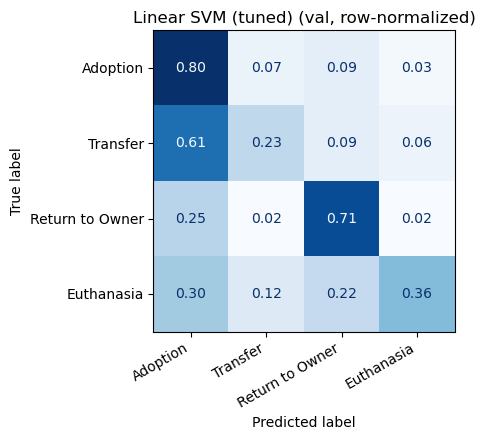

In [5]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Linear SVM (tuned)", target="outcome_group", labels=LABELS, ordinal=False,
    results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [6]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "train_accuracy"] + [f"recall_{c}" for c in LABELS]].round(3)

,accuracy,macro_f1,train_accuracy,recall_Adoption,recall_Transfer,recall_Return to Owner,recall_Euthanasia
model,,,,,,,
Linear SVM,0.656,0.395,0.638,0.912,0.212,0.460,0.000
Linear SVM (tuned),0.627,0.465,0.608,0.800,0.230,0.712,0.363


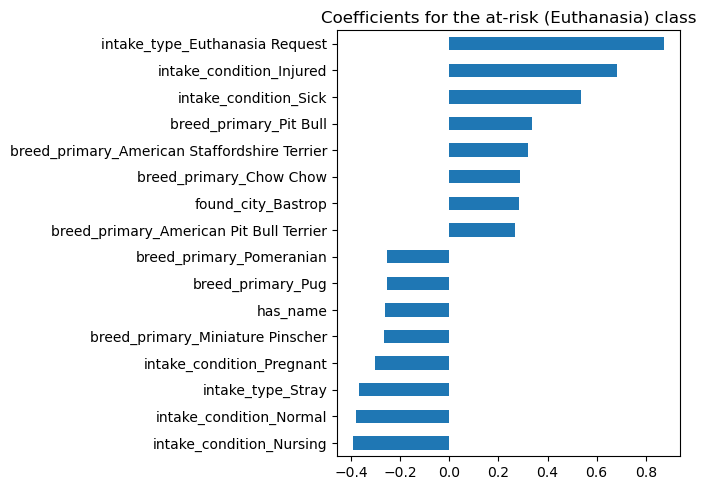

In [7]:
# Largest coefficients for the at-risk (Euthanasia) class: standardized/one-hot features,
# so magnitudes are roughly comparable. Associations, not causes.
names = pipe_tuned.named_steps["pre"].get_feature_names_out()
m = pipe_tuned.named_steps["model"]
coef = pd.DataFrame(m.coef_, index=m.classes_, columns=names).T
top = coef["Euthanasia"].sort_values()
pd.concat([top.head(8), top.tail(8)]).plot(kind="barh", figsize=(7, 5),
                                           title="Coefficients for the at-risk (Euthanasia) class")
plt.tight_layout(); plt.show()